# 05 – Các mô hình baseline (Giai đoạn 4)

**Checklist:** 4.1 → 4.6, chạy trên chuỗi tổng ở cả 3 mức nhiệt độ, sau đó chạy trên 3 zone đại diện ở mức L1.

**Bậc thang mô hình** (code ở `src/models.py`). Mỗi bậc thêm một loại thông tin hoặc một khả năng mới:

| Mô hình | Ý tưởng | Thông tin dùng | Dùng nhiệt độ? |
|---|---|---|---|
| Seasonal Naive (lag 24 / 168) | chép lại hôm qua / tuần trước | phụ tải quá khứ | không |
| MLR Tao Hong | hồi quy lịch + đa thức nhiệt độ (có M×T) | lịch, nhiệt độ, **không** có lag phụ tải | có |
| MSTL + ETS | tách mùa vụ 24 và 168, làm trơn hàm mũ phần còn lại | phụ tải quá khứ | không |
| SARIMAX(2,0,0)(1,1,0)₂₄ | ARIMA mùa vụ + Fourier tuần + nhiệt độ | lag phụ tải + nhiệt độ | có |
| LightGBM | cây tăng cường gradient | lag ≥ 24, lịch, ngày lễ, nhiệt độ | có |

**Mô hình dùng nhiệt độ thế nào ở từng mức:**
- **L1:** chỉ có nhiệt độ trễ 24 giờ và thống kê nhiệt độ ngày D−1.
- **L2:** nhiệt độ dự báo (notebook 04).
- **L3:** nhiệt độ thật.

**Quy trình chung:** fit lại vào ngày 1 mỗi tháng, dự báo mỗi ngày bằng `ev.backtest`. Kết quả được lưu ở `results/forecasts/`, nên lần chạy sau sẽ đọc lại file chứ không chạy lại.

⏱ **Thời gian chạy lần đầu** (máy 2 nhân): khoảng 40–60 phút, phần lớn là SARIMAX (3 mức) và MSTL. Có thể để chạy qua đêm.

In [1]:
import sys

sys.path.append("..")  # để import được thư mục src/ khi notebook nằm trong notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (11, 3.5)

import json
import time

from src.data import PROCESSED, load_dataset
from src.evaluation import *
from src.experiments import run_cached
from src.models import BASELINES, USES_TEMPERATURE

df = load_dataset("system")
temp_fc = pd.read_parquet(PROCESSED / "temp_forecast_system.parquet")  # từ notebook 04
scale = mase_scale(df)
print("Mẫu số MASE (MAE seasonal naive 24 trên lịch sử):", round(scale))

Mẫu số MASE (MAE seasonal naive 24 trên lịch sử): 123893


## 4.1–4.5 Chạy toàn bộ baseline

Mức L1 chạy từ 07/2005, vì GĐ5 cần cả giai đoạn "chỉ để chấm điểm". L2 và L3 chỉ cần chạy trên validation và test.

In [2]:
t0 = time.time()
fcs = {}
for name, cfg in BASELINES.items():
    for lv in TEMP_LEVELS:
        if lv != "L1" and not USES_TEMPERATURE[cfg["model"]]:
            continue
        start = SCORE_START if (lv == "L1" and cfg["model"] != "sarimax") else VAL_START
        fcs[(name, lv)] = run_cached(df, cfg, lv, temp_fc=temp_fc, start=start)
print(f"xong sau {time.time() - t0:.0f}s")

xong sau 1s


## 4.6 Bảng kết quả

Các mô hình không dùng nhiệt độ cho kết quả giống nhau ở mọi mức, nên chỉ có một dòng.

In [3]:
def subset(fc, a, b):
    return fc[(fc["origin"] >= a) & (fc["origin"] <= b)]


rows = []
for (name, lv), fc in fcs.items():
    for per, (a, b) in {
        "validation": (VAL_START, VAL_END),
        "test": (TEST_START, TEST_END),
    }.items():
        m = metrics(subset(fc, a, b), scale)
        rows.append(
            {
                "mo_hinh": name,
                "muc": lv if USES_TEMPERATURE[BASELINES[name]["model"]] else "-",
                "giai_doan": per,
                **m,
            }
        )
res = pd.DataFrame(rows)
res.to_csv("../results/tables/4_6_baselines_system.csv", index=False)
tab = res.pivot_table(
    index=["mo_hinh", "muc"], columns="giai_doan", values=["MAPE", "MASE"]
)
tab = tab.reindex(columns=["validation", "test"], level=1).round(3)
tab.sort_values(("MAPE", "validation"))

MAPE               MASE       
giai_doan     validation    test validation   test
mo_hinh   muc                                     
lgbm      L3       3.590   3.563      0.499  0.513
mlr       L3       4.833   5.108      0.652  0.698
sarimax   L3       5.134   5.075      0.691  0.720
lgbm      L2       5.514   5.325      0.791  0.792
sarimax   L2       6.272   6.015      0.872  0.874
mlr       L2       6.549   6.359      0.927  0.919
lgbm      L1       6.766   6.479      0.949  0.936
sarimax   L1       6.826   6.758      0.946  0.974
snaive24  -        8.051   8.039      1.109  1.141
mstl_ets  -        8.555   8.564      1.179  1.228
mlr       L1       8.640   8.050      1.187  1.129
snaive168 -       13.766  14.212      1.870  2.038

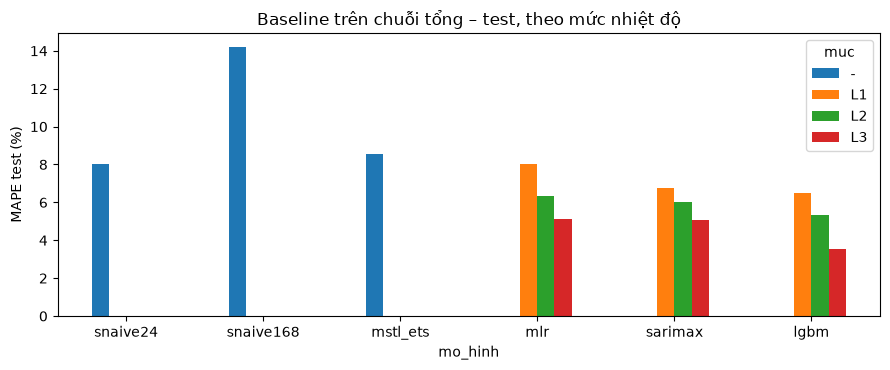

In [4]:
piv = res[res.giai_doan == "test"].pivot_table(
    index="mo_hinh", columns="muc", values="MAPE"
)
piv = piv.reindex(["snaive24", "snaive168", "mstl_ets", "mlr", "sarimax", "lgbm"])
ax = piv.plot.bar(figsize=(9, 3.8), rot=0)
ax.set_ylabel("MAPE test (%)")
ax.set_title("Baseline trên chuỗi tổng – test, theo mức nhiệt độ")
plt.tight_layout()
plt.savefig("../results/figures/4_6_baselines_test.png", dpi=120)
plt.show()

### Kiểm định DM ở mức L1 trên test

So sánh mô hình tốt nhất ở L1 (theo validation) với từng mô hình còn lại. Vì so sánh nhiều cặp cùng lúc, p-value được hiệu chỉnh theo Holm.

In [5]:
l1 = {n: subset(fc, TEST_START, TEST_END) for (n, lv), fc in fcs.items() if lv == "L1"}
best_l1 = (
    res[(res.giai_doan == "validation") & (res.muc.isin(["L1", "-"]))]
    .sort_values("MAPE")
    .iloc[0]["mo_hinh"]
)
dm = pd.DataFrame(
    {
        n: dm_test(daily_loss(l1[best_l1]), daily_loss(f))
        for n, f in l1.items()
        if n != best_l1
    }
).T
dm["p_holm"] = holm(dm["p_value"])
print("Mô hình tốt nhất ở L1 (chọn theo validation):", best_l1)
dm.round(4)

Mô hình tốt nhất ở L1 (chọn theo validation): lgbm


,mean_diff,DM,p_value,n_days,p_holm
snaive24,-1.5600,-7.6905,0.0000,365.0,0.0000
snaive168,-7.7334,-10.9639,0.0000,365.0,0.0000
mlr,-1.5707,-6.6457,0.0000,365.0,0.0000
mstl_ets,-2.0852,-6.7970,0.0000,365.0,0.0000
sarimax,-0.2793,-1.3690,0.1718,365.0,0.1718


### Sai số theo mùa và loại ngày (L1, test)

In [6]:
def by_group(fc):
    f = fc[~fc.is_imputed].copy()
    f["ape"] = (f.y - f.yhat).abs() / f.y * 100
    f["mua"] = [season_of(m) for m in f.datetime.dt.month]
    day = f.datetime.dt.normalize()
    f["loai_ngay"] = np.where(
        df.loc[f.datetime, "is_holiday"].values == 1,
        "le",
        np.where(f.datetime.dt.dayofweek >= 5, "cuoi_tuan", "thuong"),
    )
    return f


g = pd.concat({n: by_group(f) for n, f in l1.items()}, names=["mo_hinh"]).reset_index(
    level=0
)
pd.concat(
    [
        g.pivot_table(index="mo_hinh", columns="mua", values="ape"),
        g.pivot_table(index="mo_hinh", columns="loai_ngay", values="ape"),
    ],
    axis=1,
).round(2)

C:\Users\Admin\AppData\Local\Temp\ipykernel_5732\243009435.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  np.where(f.datetime.dt.dayofweek >= 5, "cuoi_tuan", "thuong"))
C:\Users\Admin\AppData\Local\Temp\ipykernel_5732\243009435.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  np.where(f.datetime.dt.dayofweek >= 5, "cuoi_tuan", "thuong"))
C:\Users\Admin\AppData\Local\Temp\ipykernel_5732\243009435.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  np.where(f.datetime.dt.dayofweek >= 5, "cuoi_tuan", "thuong"))
C:\Users\Admin\AppData\Local\Temp\ipykernel_5732\243009435.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  np.where(f.datetime.dt.dayofweek >= 5, 

,dong,he,thu,xuan,cuoi_tuan,le,thuong
mo_hinh,,,,,,,
lgbm,8.44,6.21,5.69,5.59,6.62,7.44,6.38
mlr,9.32,7.65,7.44,7.79,7.80,13.12,7.95
mstl_ets,10.51,7.79,7.89,8.07,8.82,11.62,8.34
sarimax,7.93,6.10,6.40,6.61,7.65,8.64,6.31
snaive168,18.24,15.12,13.66,9.88,12.24,22.65,14.70
snaive24,10.12,6.76,7.57,7.72,8.95,9.45,7.60


## Chạy trên 3 zone đại diện (L1)

Mỗi zone dùng nhiệt độ của trạm đã chọn ở notebook 02. Vì mỗi zone có mức tải khác nhau, MASE được tính với mẫu số của chính zone đó. SARIMAX được bỏ qua ở bước này cho đỡ tốn thời gian.

In [7]:
with open("../results/tables/2_14_zone_dai_dien.json") as f:
    chosen = json.load(f)
rows = []
for nhom, z in chosen.items():
    dz = load_dataset(z)
    sc = mase_scale(dz)
    for name in ("snaive24", "mlr", "mstl_ets", "lgbm"):
        fc = run_cached(dz, BASELINES[name], "L1", series=z, start=VAL_START)
        for per, (a, b) in {
            "validation": (VAL_START, VAL_END),
            "test": (TEST_START, TEST_END),
        }.items():
            rows.append(
                {
                    "zone": f"{z} ({nhom})",
                    "mo_hinh": name,
                    "giai_doan": per,
                    **metrics(subset(fc, a, b), sc),
                }
            )
zres = pd.DataFrame(rows)
zres.to_csv("../results/tables/4_6_baselines_zones_L1.csv", index=False)
zres.pivot_table(
    index=["zone", "mo_hinh"], columns="giai_doan", values=["MAPE", "WAPE", "MASE"]
).round(2)

  xong mstl_ets_window_weeks-8 [L1] trong 1829s
  xong lgbm_num_leaves-31_target-ratio_train_years-None [L1] trong 40s
  xong snaive_lag-24 [L1] trong 14s
  xong mlr_month_temp-True_poly-3_train_years-None [L1] trong 425s
  xong mstl_ets_window_weeks-8 [L1] trong 1930s
  xong lgbm_num_leaves-31_target-ratio_train_years-None [L1] trong 34s


MAPE             MASE              WAPE           
giai_doan                  test validation  test validation   test validation
zone            mo_hinh                                                      
10 (doi_che_do) lgbm       8.09       7.76  1.49       0.72   8.56       7.97
                mlr       31.04       9.31  7.34       0.85  42.22       9.32
                mstl_ets  10.13       9.87  1.83       0.91  10.54       9.99
                snaive24  11.13      11.37  1.89       1.02  10.86      11.23
4 (on_dinh)     lgbm      24.85      17.37  0.78       0.83   6.71       7.08
                mlr       27.77      20.34  1.02       1.17   8.77       9.99
                mstl_ets  27.99      20.15  1.01       1.07   8.73       9.15
                snaive24  25.79      18.74  0.99       1.03   8.56       8.84
9 (bien_dong)   lgbm        inf      42.57  0.87       0.99  17.69      19.11
                mlr         inf      45.63  1.00       1.03  20.34      20.05
                mstl_ets    inf      46.87  1.19       1.28  24.15      24.88
                snaive24    inf      41.92  1.02       1.08  20.63      20.88

**Vì sao ở zone em đọc WAPE thay vì MAPE.** Zone 4 và zone 9 có những giờ phụ tải gần bằng 0 (zone 9 có cả giờ bằng đúng 0, khi tải công nghiệp ngừng). Ở những giờ đó |sai số| / y bị nổ, nên MAPE của zone 9 ra `inf` và MAPE của zone 4 bị đẩy lên khoảng 25%, dù sai số thực tế không lớn. WAPE = Σ|sai số| / Σ phụ tải không gặp vấn đề này. Vì vậy với các zone, **WAPE là thước đo ra quyết định**; chuỗi tổng không có giờ nào gần 0 nên vẫn giữ MAPE như đã chốt ở GĐ3. Đây là quyết định em cần báo thầy.

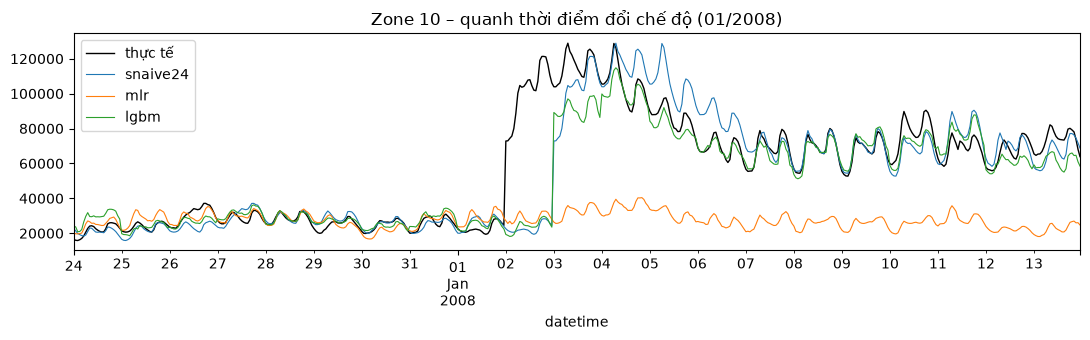

In [8]:
# Zone 10 sau khi đổi chế độ: dự báo tháng 01/2008 của từng mô hình
z10 = [z for z in chosen.values() if z == 10]
if z10:
    d10 = load_dataset(10)
    w = slice("2007-12-24", "2008-01-13 23:00")
    ax = d10.loc[w, "load"].plot(color="k", lw=1, label="thực tế", figsize=(11, 3.5))
    for name in ("snaive24", "mlr", "lgbm"):
        fc = run_cached(
            d10, BASELINES[name], "L1", series=10, start=VAL_START
        ).set_index("datetime")["yhat"]
        fc.loc[w].plot(ax=ax, lw=0.8, label=name)
    ax.legend()
    ax.set_title("Zone 10 – quanh thời điểm đổi chế độ (01/2008)")
    plt.tight_layout()
    plt.savefig("../results/figures/4_6_zone10_doi_che_do.png", dpi=120)
    plt.show()

## Nhận xét

### Chuỗi tổng
1. **Thông tin nhiệt độ tạo ra khác biệt lớn nhất.** Cùng là LightGBM, MAPE test đi từ 6,48% (L1) xuống 5,32% (L2) rồi 3,58% (L3). Khoảng gần 3 điểm % giữa L1 và L3 chính là giá trị của việc *biết trước* nhiệt độ. Trước đây em dùng nhiệt độ thật (tương đương L3), nên kết quả trông tốt hơn thực tế rất nhiều. Đây đúng là điểm thầy đã chỉ ra.
2. **MLR Tao Hong phụ thuộc nhiệt độ nhiều nhất.** Ở L3 nó đứng thứ hai (5,11%), nhưng ở L1 tụt xuống 8,05%, ngang seasonal naive. Lý do: mô hình không có lag phụ tải, nên khi chỉ có nhiệt độ của hôm qua thì gần như mất hết thông tin.
3. **Ở L1 (bản chính), LightGBM tốt nhất (6,48%), sau đó là SARIMAX (6,73%).**
   - Hai mô hình này khác nhau không có ý nghĩa thống kê (DM, p ≈ 0,22).
   - Cả hai thắng có ý nghĩa seasonal naive 24, MLR và MSTL+ETS (p < 0,001 sau hiệu chỉnh Holm).
4. **Lag 24 tốt hơn lag 168 rất xa, và MSTL+ETS không thắng nổi seasonal naive 24.** Với bài dự báo ngày tới, thông tin của hôm qua là mạnh nhất.
5. **Khó nhất là mùa đông và ngày lễ.** MLR bản vanilla không có biến ngày lễ nên sai tới khoảng 13% vào ngày lễ.
6. **Thứ hạng các mô hình giữ nguyên giữa validation và test**, tức kết quả ổn định.

### Ba zone đại diện (L1, đọc theo WAPE)
- **Zone 10 (đổi chế độ):** MLR sụp đổ (WAPE ≈ 42%) vì không có lag phụ tải; xu hướng tuyến tính không thể theo kịp bước nhảy gấp 3 lần. LightGBM với `target="ratio"` thích nghi sau khoảng 1 ngày (WAPE ≈ 8,6%), như hình ở trên. Đây đúng là loại tình huống mà một giả thuyết "đổi mức tải" của LLM cần phát hiện để chọn đúng cấu hình.
- **Zone 9 (biến động):** sai số cao nhất (WAPE 18–24%) do các lần ngừng tải không báo trước, không mô hình nào dự báo được.
- **Zone 4 (ổn định):** WAPE khoảng 6,7–8,8%; LightGBM vẫn tốt nhất.

**Ý nghĩa cho ToT:** mô hình tốt nhất thay đổi theo zone và theo mức nhiệt độ, nên việc chọn cấu hình theo ngữ cảnh có ý nghĩa. GĐ5 (notebook 06) sẽ đo xem các cách chọn thông thường đã khai thác được bao nhiêu phần lợi ích này.